In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from marathon_predictor.config import PROCESSED_DIR

In [3]:
df = pd.read_parquet(PROCESSED_DIR / "berlin.parquet")
df.head()

,year,gender,nationality,split_5k,split_10k,split_15k,split_20k,time_half,split_25k,split_30k,split_35k,split_40k,time_full
0,1999,M,KEN,909.0,1821.0,2725.0,3634.0,3834.0,4494.0,5410.0,6305.0,7208.0,7604.0
1,1999,M,JPN,909.0,1821.0,2727.0,3636.0,3834.0,4496.0,5418.0,6321.0,7218.0,7617.0
2,1999,M,KEN,910.0,1821.0,2727.0,3635.0,3834.0,4495.0,5418.0,6359.0,7301.0,7711.0
3,1999,M,MAR,911.0,1823.0,2727.0,3636.0,3835.0,4496.0,5424.0,6374.0,7372.0,7796.0
4,1999,M,KEN,910.0,1821.0,0.0,3635.0,3835.0,4495.0,5418.0,6374.0,7378.0,7837.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 678711 entries, 0 to 678710
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   year         678711 non-null  int64  
 1   gender       678709 non-null  str    
 2   nationality  678694 non-null  str    
 3   split_5k     678656 non-null  float64
 4   split_10k    678667 non-null  float64
 5   split_15k    678633 non-null  float64
 6   split_20k    678628 non-null  float64
 7   time_half    678664 non-null  float64
 8   split_25k    678634 non-null  float64
 9   split_30k    678658 non-null  float64
 10  split_35k    678651 non-null  float64
 11  split_40k    647940 non-null  float64
 12  time_full    678711 non-null  float64
dtypes: float64(10), int64(1), str(2)
memory usage: 70.1 MB


In [6]:
df.describe()

,year,split_5k,split_10k,split_15k,split_20k,time_half,split_25k,split_30k,split_35k,split_40k,time_full
count,678711.000000,678656.000000,678667.000000,678633.000000,678628.000000,678664.000000,678634.000000,678658.000000,678651.000000,647940.000000,678711.000000
mean,2009.982586,1652.467144,3344.612529,5013.524624,6708.805945,7152.524902,8537.386774,10350.829293,12112.245450,14078.806939,14912.177041
std,5.920815,294.391893,527.544458,801.529492,1086.343230,1182.213176,1453.280976,1796.713359,2426.964996,2497.949842,2582.195770
min,1999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.000000,1492.000000,2991.000000,4477.000000,5976.000000,6335.000000,7538.000000,9116.000000,10692.000000,12386.000000,13112.000000
50%,2010.000000,1660.000000,3331.000000,4985.000000,6659.000000,7071.000000,8422.000000,10189.000000,11971.000000,13816.000000,14623.000000
75%,2015.000000,1833.000000,3681.000000,5514.000000,7379.000000,7886.000000,9426.000000,11447.000000,13524.000000,15614.000000,16519.000000
max,2019.000000,4215.000000,7158.000000,10539.000000,14142.000000,18217.000000,42113.000000,21847.000000,25787.000000,29777.000000,31639.000000


In [5]:
df.isna().sum()

year               0
gender             2
nationality       17
split_5k          55
split_10k         44
split_15k         78
split_20k         83
time_half         47
split_25k         77
split_30k         53
split_35k         60
split_40k      30771
time_full          0
dtype: int64

The split at 40k seems to be missing for a lot of runners. Apart from that, almost all splits are available for further analysis.

In [19]:
sum(df["split_5k"] < 12 * 60)

6356

In [68]:
sum(df["split_5k"] == 0)

6356

One can conclude that over 6000 5k-times are missing/are zero and therefore not correctly measured.

In [78]:
split_cols = [f"split_{i}k" for i in range(5, 41, 5)]

falsche_reihenfolge = (df[split_cols].replace(0, np.nan).diff(axis=1) < 0).any(axis=1)
print(
    falsche_reihenfolge.sum(),
    "Runners with not increasing split times (split times that are not in the correct order).",
)
df[falsche_reihenfolge].head()

19 Runners with not increasing split times (split times that are not in the correct order).


,year,gender,nationality,split_5k,split_10k,split_15k,split_20k,time_half,split_25k,split_30k,split_35k,split_40k,time_full
32532,2000,M,196,3779.0,5565.0,7272.0,9064.0,14899.0,10784.0,12501.0,14200.0,7653.0,15260.0
67822,2002,M,ESP,966.0,1951.0,2921.0,3891.0,4105.0,42113.0,5820.0,6790.0,7747.0,8169.0
93459,2003,M,197,2335.0,3563.0,4756.0,5943.0,7140.0,8297.0,9490.0,5014.0,NaN,10015.0
93906,2003,M,196,2470.0,3710.0,4958.0,6198.0,7453.0,8712.0,9981.0,5224.0,NaN,10532.0
96771,2003,M,196,2838.0,4186.0,5582.0,6993.0,8459.0,9887.0,11370.0,5905.0,NaN,12018.0


In [79]:
(df[split_cols + ["time_half", "time_full"]] == 0).sum()

split_5k     6356
split_10k     907
split_15k     988
split_20k     892
split_25k     692
split_30k     828
split_35k    6632
split_40k     969
time_half     464
time_full       2
dtype: int64

In [82]:
df[df["split_35k"] == 0].groupby("year").size()

year
1999     291
2000      80
2001       1
2002      38
2003       8
2004      10
2005      42
2006      46
2007      25
2008      33
2009      55
2010      57
2011    5519
2012      45
2013      20
2014      46
2015      31
2016      65
2017     140
2018      80
dtype: int64

It seems that in the year 2011, there were some (technical) problems with measuring the split times at 35km which needs to be considered in the following analysis.

Text(0.5, 1.0, 'Distribution of finish times')

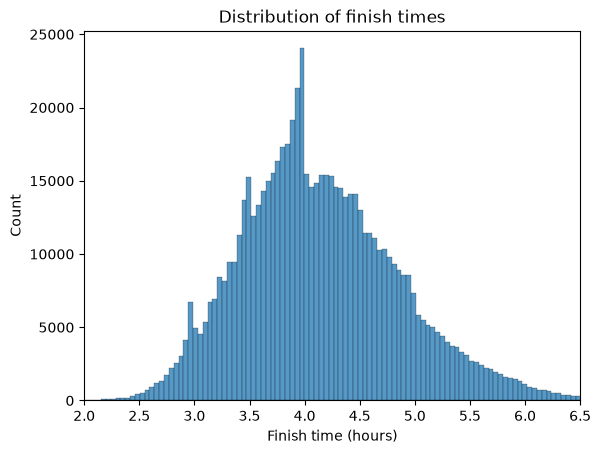

In [20]:
ax = sns.histplot(df["time_full"] / 3600, bins=200)
ax.set_xlabel("Finish time (hours)")
ax.set_ylabel("Count")
ax.set_xlim(2, 6.5)
ax.set_title("Distribution of finish times")

One can clearly see that there are a lot more runners finishing a few minutes below for example 3, 3.5, 4, 4.5, 5 hours than there are finishing a little bit over these times.

<Axes: title={'center': 'Number of runners per year'}, xlabel='year'>

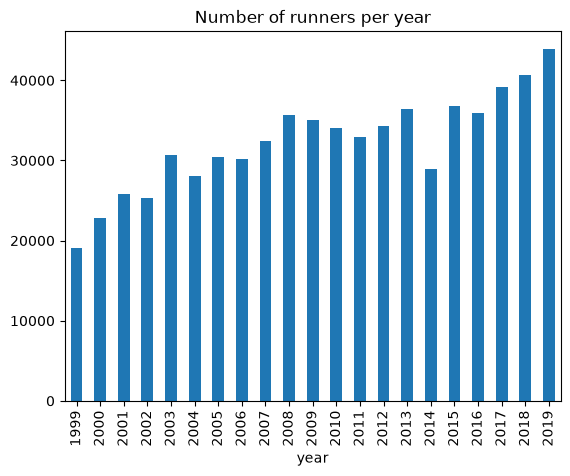

In [24]:
runners_per_year = df.groupby("year").size()
runners_per_year.plot(kind="bar", title="Number of runners per year")

There is a clear upwards trend in the number of finishers of the Berlin marathon over the years. 

<Axes: title={'center': 'Ratio of women per year'}, xlabel='year'>

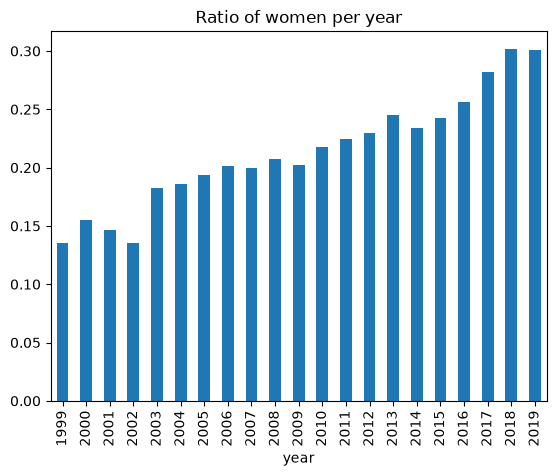

In [28]:
women_per_year = df[df["gender"] == "F"].groupby("year").size()
women_ratio_per_year = women_per_year / runners_per_year
women_ratio_per_year.plot(kind="bar", title="Ratio of women per year")

The ratio of women finishing the marathon is increasing over the years.

In [36]:
time_full = df["time_full"]
time_half = df["time_half"]
time_second_half = time_full - time_half

negative_split_times = sum(time_second_half < time_half)
negative_split_ratio = negative_split_times / len(df)
print(
    f"{round(negative_split_ratio * 100, 3)}% of runners had a negative split (second half faster than first half)."
)

16.313% of runners had a negative split (second half faster than first half).


In [ ]:
ratio_ten_percent_slower_than_first_half = sum(time_second_half > 1.1 * time_half) / len(df)
print(
    f"{round(ratio_ten_percent_slower_than_first_half * 100, 3)}% of runners had a split that was 10% slower than the first half."
)

38.48% of runners had a split that was 10% slower than the first half.


In [85]:
ratio_ten_percent_slower_than_first_half_women = sum(
    time_second_half[df["gender"] == "F"] > 1.1 * time_half[df["gender"] == "F"]
) / len(df[df["gender"] == "F"])
ratio_ten_percent_slower_than_first_half_men = sum(
    time_second_half[df["gender"] == "M"] > 1.1 * time_half[df["gender"] == "M"]
) / len(df[df["gender"] == "M"])
print(
    f"""{round(ratio_ten_percent_slower_than_first_half_women * 100, 3)}% 
    of women had a split that was 10% slower than the first half."""
)
print(
    f"""{round(ratio_ten_percent_slower_than_first_half_men * 100, 3)}% 
    of men had a split that was 10% slower than the first half."""
)

33.259% 
    of women had a split that was 10% slower than the first half.
39.962% 
    of men had a split that was 10% slower than the first half.


Men have a higher percentage of slowing down more than 10% in the second half than women. This could be caused by the fact that men tend to exaggerate, visible in the slowdown percentages.

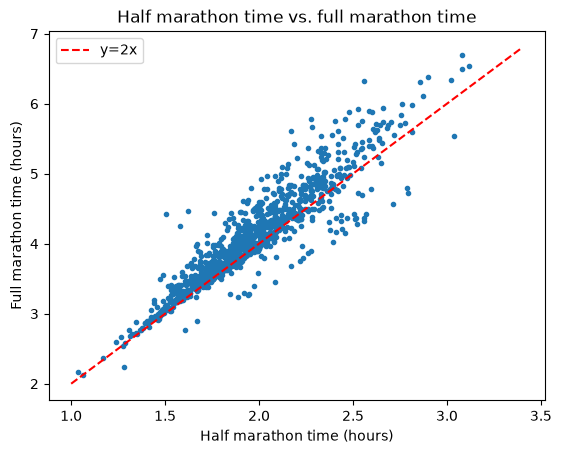

In [67]:
plot_data = df.sample(n=1000, random_state=42)
grid = np.arange(1, 3.5, 0.1)
plt.plot(plot_data["time_half"] / 3600, plot_data["time_full"] / 3600, ".")
plt.plot(grid, 2 * np.array(grid), "r--", label="y=2x")


plt.xlabel("Half marathon time (hours)")
plt.ylabel("Full marathon time (hours)")
plt.title("Half marathon time vs. full marathon time")
plt.legend()

Most of the runners lie above the $f(x) = 2x$ line indicating a slower second half in the marathon.

In [66]:
my_finish_time_2026 = 3 * 3600 + 29 * 60 + 48
my_finish_time_quantile = (df["time_full"] < my_finish_time_2026).mean()
print(
    f"My finish time of 3:29:48 in 2026 would be faster than {round((1 - my_finish_time_quantile) * 100, 2)}% of runners in the dataset."
)

My finish time of 3:29:48 in 2026 would be faster than 81.53% of runners in the dataset.
